<a href="https://colab.research.google.com/github/princeallaramadji/m3-iml-devoirs/blob/main/Devoir1__Titanic__Prince.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Devoir 1 : effet de max_depth sur un arbre de décision (Titanic)**

Objectif : prédire la survie des passagers du Titanic avec un arbre de décision et étudier l'effet de la profondeur maximale (max_depth, de 1 à 10) sur l'accuracy train et test, pour repérer l'overfitting.
Données : dataset Titanic de seaborn (891 passagers), features pclass, sex, age, sibsp, parch, fare, cible survived.
Méthode : découpage 80/20 stratifié (random_state=42), imputation de age par la médiane du train, puis entraînement d'un arbre pour chaque profondeur.

Etape 1: chargment

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = sns.load_dataset('titanic')
print(df.shape)

(891, 15)


Étape 2 : features, cible, encodage de sex

sex est encodé en 0/1 car l'arbre attend des valeurs numériques. age a 177 valeurs manquantes, à traiter après le découpage

In [20]:
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
X = df[cols].copy()
y = df['survived']
X['sex'] = X['sex'].map({'male': 0, 'female': 1})
print(X.isna().sum())

pclass      0
sex         0
age       177
sibsp       0
parch       0
fare        0
dtype: int64


Étape 3 : découpage train/test

stratify=y garde la même proportion de survivants dans train et test, et random_state=42 rend le résultat reproductible

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

(712, 6) (179, 6)
{0: 439, 1: 273} {0: 110, 1: 69}


Étape 4 : imputer age avec la médiane du TRAIN

La médiane est calculée sur le train uniquement, puis appliquée au test, pour éviter toute fuite de données. »
Étape 5 : « Pour chaque profondeur de 1 à 10, on entraîne un arbre et on mesure l'accuracy sur le train et sur le test.

In [22]:
mediane_age = X_train['age'].median()
print('Médiane (train) :', mediane_age)
X_train['age'] = X_train['age'].fillna(mediane_age)
X_test['age'] = X_test['age'].fillna(mediane_age)
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

Médiane (train) : 28.5
0 0


Étape 5 : boucle sur max_depth de 1 à 10

In [23]:
depths = range(1, 11)
acc_train, acc_test = [], []
for d in depths:
    arbre = DecisionTreeClassifier(max_depth=d, random_state=42)
    arbre.fit(X_train, y_train)
    acc_train.append(arbre.score(X_train, y_train))
    acc_test.append(arbre.score(X_test, y_test))

resultats = pd.DataFrame({'max_depth': depths,
                          'acc_train': acc_train,
                          'acc_test': acc_test}).round(3)
resultats

,max_depth,acc_train,acc_test
0,1,0.789,0.777
1,2,0.805,0.760
2,3,0.827,0.810
3,4,0.834,0.771
4,5,0.864,0.754
5,6,0.881,0.777
6,7,0.888,0.777
7,8,0.912,0.788
8,9,0.923,0.788
9,10,0.933,0.777


Étape 6 : le graphique

Le graphique permet de comparer les deux courbes et de repérer où elles divergent

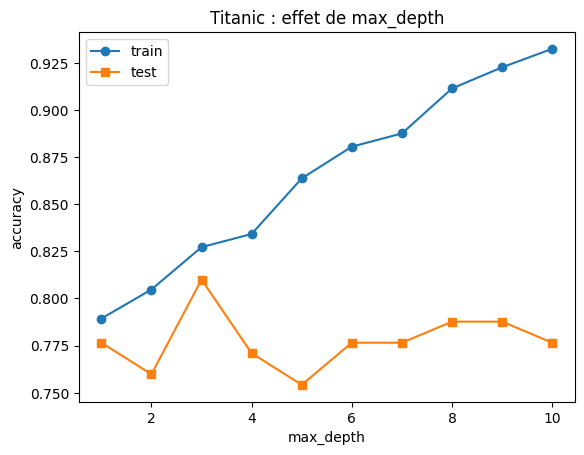

In [24]:
plt.plot(depths, acc_train, 'o-', label='train')
plt.plot(depths, acc_test, 's-', label='test')
plt.xlabel('max_depth'); plt.ylabel('accuracy')
plt.title('Titanic : effet de max_depth'); plt.legend(); plt.show()

Étape 7 : Reponse aux questions

Q1. L'overfitting apparaît à partir de max_depth = 4 ou 5. On le voit parce que l'accuracy train continue de monter (0.83 à 0.93) alors que l'accuracy test ne progresse plus et fluctue autour de 0.77. L'écart train/test, de 0.02 à la profondeur 3, atteint 0.11 à la profondeur 5 et 0.16 à la profondeur 10 : l'arbre mémorise le train.

Q2. Je retiens max_depth = 3, car c'est là que l'accuracy test est maximale (0.810) avec un écart train/test faible (0.017), donc un arbre simple et qui généralise bien. Ce choix reste fragile : il repose sur un seul découpage de seulement 179 passagers dans le test, et les différences entre profondeurs sont de quelques passagers. Avec d'autres random_state, j'ai constaté que la meilleure profondeur change (3, 4, 6 ou 7 selon la graine). Choisir sur le test le rend aussi légèrement optimiste. La validation croisée donnerait une estimation plus stable.

Q3. Deux erreurs à éviter :

Calculer la médiane de age sur tout le dataset (ou sur le test) au lieu du train seul : c'est une fuite de données (28.0 sur tout le dataset contre 28.5 sur le train), l'évaluation devient optimiste.
Oublier stratify=y ou random_state=42 : les proportions de survivants changent entre train et test, et les résultats ne sont plus reproductibles. (Autre erreur valable : régler max_depth sur le test sans le préciser.)

Conclusion : l'accuracy train augmente avec la profondeur (0.79 à 0.93) alors que l'accuracy test plafonne autour de 0.77 à 0.81, signe d'overfitting. Je retiens max_depth = 3, à confirmer par validation croisée.